# AI Applications & Mini Project 2 — Quality control

**Digital Foundation for Chemical Engineers**  \n
Duration: 60 minutes

## Today’s goal
Use a quality-data CSV to examine product variation, identify batches for review, and understand where AI can assist laboratory and process quality workflows.

## 1. AI in quality control (10 min)

AI applications may classify images for visible defects, predict a quality value from process data, prioritise samples, or detect unusual laboratory results. The quality specification, validated measurement method, and accountable human decision remain essential.

A useful project question is specific: Can process readings help identify batches likely to require quality review?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

quality_data = pd.read_csv('data/quality_batches_120.csv')
quality_data['timestamp'] = pd.to_datetime(quality_data['timestamp'])
quality_data.head()

,timestamp,batch_id,reactor,inlet_temperature_c,conversion_percent,product_purity_percent,lab_result
0,2026-02-02 08:00:00,Q2001,R1,72.0,88.5,96.20,REVIEW
1,2026-02-02 09:00:00,Q2001,R2,72.6,88.5,96.39,REVIEW
2,2026-02-02 10:00:00,Q2001,R3,73.2,89.0,96.58,REVIEW
3,2026-02-02 11:00:00,Q2001,R1,73.8,89.9,96.77,REVIEW
4,2026-02-02 12:00:00,Q2001,R2,74.4,89.9,96.96,REVIEW


## 2. Explore quality variation (12 min)

Start by checking distributions and the number of review records. Do not assume that a lab label is perfect; it is a reference outcome that a future model would need to examine and validate.

In [4]:
display(quality_data[['conversion_percent', 'product_purity_percent']].describe())
print(quality_data['lab_result'].value_counts())
display(quality_data.groupby('reactor')[['conversion_percent', 'product_purity_percent']].mean())

,conversion_percent,product_purity_percent
count,120.000000,120.000000
mean,91.192500,97.043333
std,1.946821,0.549290
min,88.000000,96.200000
25%,89.475000,96.580000
50%,91.150000,96.960000
75%,92.800000,97.530000
max,94.700000,97.910000


lab_result
PASS      77
REVIEW    43
Name: count, dtype: int64


,conversion_percent,product_purity_percent
reactor,,
R1,91.5500,97.0375
R2,91.0250,97.0550
R3,91.0025,97.0375


In [7]:
print(quality_data['batch_id'].value_counts())


batch_id
Q2001    8
Q2002    8
Q2003    8
Q2004    8
Q2005    8
Q2006    8
Q2007    8
Q2008    8
Q2009    8
Q2010    8
Q2011    8
Q2012    8
Q2013    8
Q2014    8
Q2015    8
Name: count, dtype: int64


In [8]:
print(quality_data['reactor'].value_counts())


reactor
R1    40
R2    40
R3    40
Name: count, dtype: int64


In [9]:
display(quality_data.groupby('lab_result')[['conversion_percent', 'product_purity_percent']].mean())

,conversion_percent,product_purity_percent
lab_result,,
PASS,92.366234,97.075974
REVIEW,89.090698,96.984884


In [10]:
display(quality_data.groupby('batch_id')[['conversion_percent', 'product_purity_percent']].mean())

,conversion_percent,product_purity_percent
batch_id,,
Q2001,89.8750,96.8650
Q2002,92.0250,96.9600
Q2003,90.7625,97.0550
Q2004,91.3125,97.1500
Q2005,91.7875,97.1575
Q2006,90.5250,96.8650
Q2007,92.7500,96.9600
Q2008,89.8750,97.0550
Q2009,91.9625,97.1500


**Try it (4 min):** Which reactor has the highest average purity? How many rows are labelled REVIEW?

**Challenge:** Calculate mean inlet temperature for PASS and REVIEW groups using groupby.

## 3. Visualise a possible relationship (12 min)

A scatter plot helps generate hypotheses. It does not prove that one variable causes another; process conditions, measurement uncertainty, and unobserved variables matter.

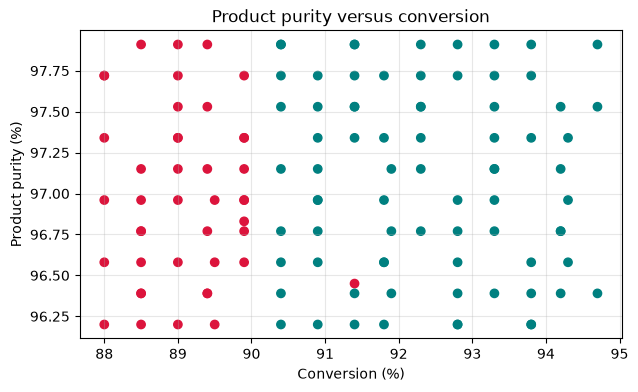

In [13]:
colors = quality_data['lab_result'].map({'PASS': 'teal', 'REVIEW': 'crimson'})
plt.figure(figsize=(7, 4))
plt.scatter(quality_data['conversion_percent'], quality_data['product_purity_percent'], c=colors)
plt.title('Product purity versus conversion')
plt.xlabel('Conversion (%)')
plt.ylabel('Product purity (%)')
plt.grid(alpha=0.3)
plt.show()

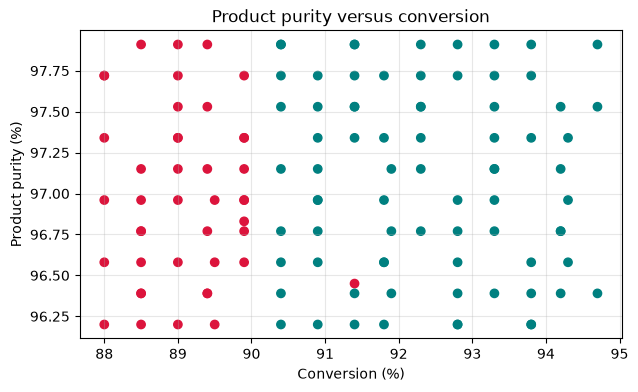

,timestamp,batch_id,reactor,inlet_temperature_c,conversion_percent,product_purity_percent,lab_result
35,2026-02-03 19:00:00,Q2005,R3,76.8,91.4,96.45,REVIEW


In [20]:
colors = quality_data['lab_result'].map({'PASS': 'teal', 'REVIEW': 'crimson'})
plt.figure(figsize=(7, 4))
plt.scatter(quality_data['conversion_percent'], quality_data['product_purity_percent'], c=colors)
plt.title('Product purity versus conversion')
plt.xlabel('Conversion (%)')
plt.ylabel('Product purity (%)')
plt.grid(alpha=0.3)
plt.show()
special_case = quality_data[(quality_data['lab_result']=='REVIEW') & (quality_data['conversion_percent']>91)]
display(special_case)

## 4. Screening versus prediction (15 min)

Below is a simple quality-screening rule. A trained ML classifier could combine more variables and learn from historic labelled outcomes, but it must be evaluated on unseen data and monitored after deployment.

In [21]:
screened = quality_data.copy()
screened['screening_status'] = 'OK'
screened.loc[(screened['conversion_percent'] < 90) |
             (screened['product_purity_percent'] < 97.0), 'screening_status'] = 'REVIEW'
print(pd.crosstab(screened['lab_result'], screened['screening_status']))
display(screened[screened['screening_status'] == 'REVIEW'].head())

screening_status  OK  REVIEW
lab_result                  
PASS              40      37
REVIEW             0      43


,timestamp,batch_id,reactor,inlet_temperature_c,conversion_percent,product_purity_percent,lab_result,screening_status
0,2026-02-02 08:00:00,Q2001,R1,72.0,88.5,96.20,REVIEW,REVIEW
1,2026-02-02 09:00:00,Q2001,R2,72.6,88.5,96.39,REVIEW,REVIEW
2,2026-02-02 10:00:00,Q2001,R3,73.2,89.0,96.58,REVIEW,REVIEW
3,2026-02-02 11:00:00,Q2001,R1,73.8,89.9,96.77,REVIEW,REVIEW
4,2026-02-02 12:00:00,Q2001,R2,74.4,89.9,96.96,REVIEW,REVIEW


## Pair task (10 min)
Compare the screening result with lab_result. Describe one false alarm and one missed case if present. Which is more costly in this context, and why?

**Challenge:** Propose three additional process or laboratory columns that could make a future model more useful.

## Exit check
You can use quality data to support review prioritisation and explain why models must be validated against reliable reference outcomes. Next: process safety and anomaly detection.